In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_49.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_90.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_77.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_66.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_54.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_42.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_81.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_72.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final

In [2]:
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("Logged in to Hugging Face.")
else:
    print("HF_TOKEN not found. Proceeding without Hugging Face authentication.")

Logged in to Hugging Face.


In [3]:
!pip install -q openai-whisper language_tool_python
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 11.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 84.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [4]:
import os, re, json
import gc
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import torch
import whisper
import spacy
import language_tool_python
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM,
                          WhisperFeatureExtractor, WhisperModel, AutoFeatureExtractor, WavLMModel,
                          Wav2Vec2Processor, Wav2Vec2ForCTC)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device, "| GPUs:", torch.cuda.device_count())

def on_all_gpus(func, items, load_models):
    # Splits the items between all GPUs and runs func(part, device, models) on every GPU at the same time.
    # The models are loaded first, one GPU after the other, in the main thread. Loading models from two
    # threads at once breaks in recent versions of transformers ("Cannot copy out of meta tensor").
    # func must return one result per item. The results come back in the original order.
    devs = [f"cuda:{i}" for i in range(torch.cuda.device_count())] or ["cpu"]
    models = [load_models(d) for d in devs]
    parts = [items[i::len(devs)] for i in range(len(devs))]

    def run(part, dev, m):
        try:
            if dev != "cpu":
                torch.cuda.set_device(dev)
            return func(part, dev, m)
        except Exception as e:
            print("ERROR on", dev, "->", repr(e))      # shown right away, not only when the other GPU is finished
            raise

    with ThreadPoolExecutor(max_workers=len(devs)) as pool:
        jobs = [pool.submit(run, p, d, m) for p, d, m in zip(parts, devs, models)]
        results = [j.result() for j in jobs]
    merged = [None] * len(items)
    for i, r in enumerate(results):
        merged[i::len(devs)] = r
    del models
    gc.collect()
    torch.cuda.empty_cache()
    return merged

Using cuda | GPUs: 2


In [5]:
DATA = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/"

train = pd.read_csv(DATA + "train.csv")
test = pd.read_csv(DATA + "test.csv")
print(train.shape, test.shape)
print(train.head())

train["path"] = DATA + "train/" + train["filename"]
test["path"] = DATA + "test/" + test["filename"]
assert os.path.exists(train["path"][0]) and os.path.exists(test["path"][0]), "check the audio folder names"

y = train["label"].values
n_train = len(train)

# train and test together, so every feature is built the same way for both
data = pd.concat([train, test], ignore_index=True)
print(len(data), "clips in total")

(769, 2) (216, 2)
        filename  label
0  audio_192.wav    3.0
1  audio_436.wav    3.0
2  audio_447.wav    3.5
3  audio_126.wav    2.0
4   audio_61.wav    2.0
985 clips in total


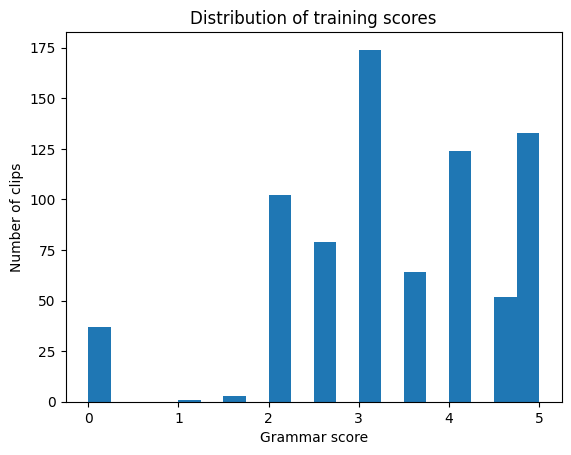

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
dtype: float64


In [6]:
plt.hist(y, bins=20)
plt.xlabel("Grammar score")
plt.ylabel("Number of clips")
plt.title("Distribution of training scores")
plt.show()
print(pd.Series(y).describe())

In [7]:
# clip lengths: the test clips are shorter than the train clips
durations = np.array([librosa.get_duration(path=p) for p in data["path"]])
print("train mean length:", durations[:n_train].mean().round(1), "s")
print("test mean length :", durations[n_train:].mean().round(1), "s")

train mean length: 55.8 s
test mean length : 48.8 s


In [8]:
def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

baseline_rmse = rmse(y, np.full(n_train, y.mean()))
print("Baseline RMSE (always predict the mean):", round(baseline_rmse, 4))

Baseline RMSE (always predict the mean): 1.2382


In [9]:
PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking. I I mean, we went, we go there."

def load_whisper(dev):
    return whisper.load_model("small", device=dev)

def transcribe(paths, dev, asr):
    # transcribe a list of files with Whisper on one GPU
    out = []
    for path in tqdm(paths, desc=dev):
        audio = librosa.load(path, sr=16000)[0]
        r = asr.transcribe(audio, language="en", word_timestamps=True, condition_on_previous_text=False,
                           initial_prompt=PROMPT, fp16=(dev != "cpu"))
        probs = [w["probability"] for s in r["segments"] for w in s["words"]]
        out.append({
            "text": r["text"].strip(),
            "word_prob_mean": float(np.mean(probs)) if probs else np.nan,
            "low_conf_ratio": float(np.mean(np.array(probs) < 0.5)) if probs else np.nan,
            "logprob_mean": float(np.mean([s["avg_logprob"] for s in r["segments"]])) if r["segments"] else np.nan,
        })
    return out

if os.path.exists("transcripts.json"):
    transcripts = json.load(open("transcripts.json"))
else:
    transcripts = on_all_gpus(transcribe, list(data["path"]), load_whisper)
    json.dump(transcripts, open("transcripts.json", "w"))

data["text"] = [t["text"] if t["text"] else "." for t in transcripts]
print("empty transcripts:", sum(t["text"] == "" for t in transcripts))
print("even clips:", data["text"][0][:100])
print("odd clips :", data["text"][1][:100])

100%|████████████████████████████████████████| 461M/461M [00:01<00:00, 281MiB/s]


cuda:0:   0%|          | 0/493 [00:00<?, ?it/s]

cuda:1:   0%|          | 0/492 [00:00<?, ?it/s]

empty transcripts: 0
even clips: Umm, well, the playground is very, very beautiful and fun. There are, there are places like the merr
odd clips : The scene of a school playground, our playground looks like a very big playground having a more, mor


In [10]:
rows = []
for path in tqdm(data["path"]):
    audio = librosa.load(path, sr=16000)[0]
    dur = len(audio) / 16000
    speech = librosa.effects.split(audio, top_db=30)          # non-silent parts
    speech_time = sum(e - s for s, e in speech) / 16000
    gaps = [(speech[i + 1][0] - speech[i][1]) / 16000 for i in range(len(speech) - 1)]
    pauses = [g for g in gaps if g >= 0.25]

    # background noise: these compare quiet and loud parts of the same clip, so they do not depend on the microphone gain
    db = 20 * np.log10(librosa.feature.rms(y=audio)[0] + 1e-8)               # loudness of every short frame
    flatness = librosa.feature.spectral_flatness(y=audio)[0]                  # close to 1 for noise, low for speech
    quiet = db < np.percentile(db, 30)                                        # the quietest frames, mostly background
    rows.append({
        "snr_db": np.percentile(db, 90) - np.percentile(db, 10),             # loud parts vs quiet parts
        "quiet_flatness": flatness[quiet].mean(),                             # does the background sound like noise?
        "speech_ratio": speech_time / dur,
        "pauses_per_sec": len(pauses) / dur,
        "long_pauses_per_sec": sum(g >= 1.0 for g in pauses) / dur,
        "mean_pause": np.mean(pauses) if pauses else 0,
    })
audio_feats = pd.DataFrame(rows)
audio_feats.head()

  0%|          | 0/985 [00:00<?, ?it/s]

/tmp/ipykernel_23/303019187.py:16: RuntimeWarning: Mean of empty slice.
  "quiet_flatness": flatness[quiet].mean(),                             # does the background sound like noise?
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


,snr_db,quiet_flatness,speech_ratio,pauses_per_sec,long_pauses_per_sec,mean_pause
0,51.037750,0.007357,0.581209,0.363586,0.082633,0.877091
1,24.705708,0.065858,0.858842,0.099876,0.016646,0.549333
2,38.094849,0.050221,0.754794,0.316273,0.016646,0.621474
3,31.617306,0.006148,0.812517,0.266312,0.022193,0.522667
4,57.968433,0.192201,0.702605,0.397351,0.000000,0.492444


In [11]:
nlp = spacy.load("en_core_web_sm")

fillers = {"um", "uh", "umm", "uhh", "er", "erm", "ah", "hmm", "mm", "uhm"}

rows = []
for i, text in enumerate(tqdm(data["text"])):
    doc = nlp(text)
    words = [t for t in doc if t.is_alpha]
    n = max(len(words), 1)
    sents = list(doc.sents)
    n_sents = max(len(sents), 1)
    tags = [t.tag_ for t in doc]
    n_verbs = max(sum(t.pos_ in ("VERB", "AUX") for t in doc), 1)
    lower = [w.lower_ for w in words]

    f = {}
    f["words_per_sec"] = n / durations[i]
    f["words_per_sentence"] = n / n_sents
    f["unique_word_ratio"] = len(set(lower)) / n
    f["avg_word_length"] = np.mean([len(w.text) for w in words]) if words else 0
    f["repeated_word_ratio"] = sum(a == b for a, b in zip(lower, lower[1:])) / n
    f["filler_per100"] = 100 * sum(w in fillers for w in lower) / n
    # verb tenses
    f["past_ratio"] = tags.count("VBD") / n_verbs
    f["present3_ratio"] = tags.count("VBZ") / n_verbs
    f["present_ratio"] = tags.count("VBP") / n_verbs
    f["modal_ratio"] = tags.count("MD") / n_verbs
    # clauses and incomplete sentences
    f["clauses_per_sentence"] = sum(t.dep_ in ("advcl", "ccomp", "acl", "relcl") for t in doc) / n_sents
    fragments = 0
    for s in sents:
        has_verb = any(t.tag_ in ("VBD", "VBZ", "VBP", "MD") for t in s)
        has_subject = any(t.dep_ in ("nsubj", "nsubjpass", "expl") for t in s)
        fragments += not (has_verb and has_subject)
    f["fragment_ratio"] = fragments / n_sents
    # share of each part of speech
    for pos in ["NOUN", "VERB", "ADJ", "ADV", "PRON", "AUX", "ADP", "DET", "CCONJ", "SCONJ"]:
        f["pos_" + pos.lower()] = sum(t.pos_ == pos for t in doc) / n
    # how sure Whisper was about the words
    f["asr_word_prob"] = transcripts[i]["word_prob_mean"]
    f["asr_low_conf_ratio"] = transcripts[i]["low_conf_ratio"]
    f["asr_logprob"] = transcripts[i]["logprob_mean"]
    rows.append(f)

text_feats = pd.DataFrame(rows)
print(text_feats.shape)

  0%|          | 0/985 [00:00<?, ?it/s]

(985, 25)


In [12]:
def clean_text(text):
    text = re.sub(r"\b(um+|uh+|er+m*|ah+|hmm+|uhm)\b[,.]?", " ", text, flags=re.I)   # fillers
    text = re.sub(r"\b(you know|i mean|kind of|sort of)\b,?", " ", text, flags=re.I)  # discourse markers
    text = re.sub(r"\b(\w+(?:\s+\w+){0,2}?)(?:[,\s]+\1\b)+", r"\1", text, flags=re.I)  # repeated words
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s+([,.!?])", r"\1", text)
    return re.sub(r"^[\s,.]+", "", text).strip()

data["clean"] = [clean_text(t) for t in data["text"]]
print("Before:", data["text"][0][:150])
print("After :", data["clean"][0][:150])

removed = [1 - len(c.split()) / max(len(t.split()), 1) for t, c in zip(data["text"], data["clean"])]
print("Average share of words removed:", round(np.mean(removed), 3))

# split every clean transcript into sentences (very short pieces are dropped)
sentences = []
for c in data["clean"]:
    s = [x.strip() for x in re.split(r"(?<=[.!?])\s+", c) if len(x.split()) >= 3]
    sentences.append(s if s else [c])

Before: Umm, well, the playground is very, very beautiful and fun. There are, there are places like the merry-go-round, the swing. The students usually enjoy 
After : well, the playground is very beautiful and fun. There are places like the merry-go-round, the swing. The students usually enjoy the swing. It has to b
Average share of words removed: 0.015


In [13]:
def load_cola(dev):
    tok = AutoTokenizer.from_pretrained("textattack/roberta-base-CoLA")
    return tok, AutoModelForSequenceClassification.from_pretrained("textattack/roberta-base-CoLA").to(dev).eval()

def cola_scores(sentence_lists, dev, models):
    # for every clip: how likely is each sentence to be grammatically acceptable
    tok, cola = models
    rows = []
    for sents in tqdm(sentence_lists, desc=dev):
        enc = tok(sents, padding=True, truncation=True, max_length=128, return_tensors="pt").to(dev)
        with torch.no_grad():
            p = torch.softmax(cola(**enc).logits, -1)[:, 1].cpu().numpy()      # P(acceptable)
        rows.append({"cola_mean": p.mean(), "cola_min": p.min(), "cola_std": p.std(),
                     "cola_share_bad": (p < 0.5).mean()})
    return rows

cola_feats = pd.DataFrame(on_all_gpus(cola_scores, sentences, load_cola))

config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


cuda:0:   0%|          | 0/493 [00:00<?, ?it/s]

cuda:1:   0%|          | 0/492 [00:00<?, ?it/s]

In [14]:
def load_gpt(dev):
    tok = AutoTokenizer.from_pretrained("gpt2")
    gpt = AutoModelForCausalLM.from_pretrained("gpt2")
    gpt.lm_head.weight = gpt.transformer.wte.weight   # connect the output layer to the word embeddings
    return tok, gpt.to(dev).eval()

def gpt_loss(text, gpt_tok, gpt, dev):
    ids = gpt_tok(gpt_tok.bos_token + text, return_tensors="pt", truncation=True, max_length=256).input_ids.to(dev)
    if ids.shape[1] < 3:
        return np.nan
    with torch.no_grad():
        return gpt(ids, labels=ids).loss.item()

def gpt_scores(sentence_lists, dev, models):
    gpt_tok, gpt = models
    rows = []
    for sents in tqdm(sentence_lists, desc=dev):
        losses = [gpt_loss(s, gpt_tok, gpt, dev) for s in sents]
        rows.append({"gpt_mean": np.nanmean(losses), "gpt_max": np.nanmax(losses), "gpt_std": np.nanstd(losses)})
    return rows

gpt_feats = pd.DataFrame(on_all_gpus(gpt_scores, sentences, load_gpt))
# sanity check: normal English gets a loss of about 3-6. A value near 10 or more means the model did not load properly
print("average GPT-2 loss per word:", round(gpt_feats["gpt_mean"].mean(), 2))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

cuda:0:   0%|          | 0/493 [00:00<?, ?it/s]

cuda:1:   0%|          | 0/492 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


average GPT-2 loss per word: 4.26


In [15]:
tool = language_tool_python.LanguageTool("en-US")
ignore = ["PUNCTUATION", "CASING", "TYPOGRAPHY", "STYLE", "REDUNDANCY", "PLAIN_ENGLISH", "WIKIPEDIA"]

rows = []
for text in tqdm(data["clean"]):
    n = max(len(text.split()), 1)
    matches = [m for m in tool.check(text) if str(m.category).upper() not in ignore]
    grammar = sum(str(m.category).upper() == "GRAMMAR" for m in matches)
    rows.append({"lt_errors_per100": 100 * len(matches) / n, "lt_grammar_per100": 100 * grammar / n})
lt_feats = pd.DataFrame(rows)
tool.close()

  0%|          | 0/985 [00:00<?, ?it/s]

In [16]:
def edit_distance(a, b):
    # number of word insertions, deletions and changes needed to turn a into b
    prev = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        cur = [i]
        for j in range(1, len(b) + 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (a[i - 1] != b[j - 1])))
        prev = cur
    return prev[-1]

def plain(text):
    return re.findall(r"[a-z']+", text.lower())

def load_ctc(dev):
    proc = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
    w2v = Wav2Vec2ForCTC.from_pretrained("facebook/wav2vec2-base-960h").to(dev).eval()
    gpt_tok, gpt = load_gpt(dev)
    return proc, w2v, gpt_tok, gpt

def ctc_scores(items, dev, models):
    # items are (audio path, cleaned Whisper transcript) pairs
    proc, w2v, gpt_tok, gpt = models
    rows = []
    for path, whisper_text in tqdm(items, desc=dev):
        audio = librosa.load(path, sr=16000)[0]
        x = proc(audio, sampling_rate=16000, return_tensors="pt").input_values.to(dev)
        with torch.no_grad():
            logits = w2v(x).logits[0]
        ids = logits.argmax(-1)
        ctc_text = proc.decode(ids.cpu().numpy())
        letters = ids != proc.tokenizer.pad_token_id                       # frames that write a letter
        conf = torch.softmax(logits, -1).max(-1).values[letters].mean().item()

        whisper_words = plain(whisper_text)
        ctc_words = plain(clean_text(ctc_text))
        rows.append({
            "ctc_vs_whisper_wer": edit_distance(whisper_words, ctc_words) / max(len(whisper_words), 1),
            "ctc_length_ratio": len(ctc_words) / max(len(whisper_words), 1),
            "ctc_confidence": conf,
            "ctc_gpt_loss": gpt_loss(" ".join(ctc_words), gpt_tok, gpt, dev),
            "whisper_gpt_loss": gpt_loss(" ".join(whisper_words), gpt_tok, gpt, dev),
        })
    return rows

ctc_feats = pd.DataFrame(on_all_gpus(ctc_scores, list(zip(data["path"], data["clean"])), load_ctc))
ctc_feats["ctc_minus_whisper_loss"] = ctc_feats["ctc_gpt_loss"] - ctc_feats["whisper_gpt_loss"]
ctc_feats = ctc_feats.drop(columns=["whisper_gpt_loss"])

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

cuda:0:   0%|          | 0/493 [00:00<?, ?it/s]

cuda:1:   0%|          | 0/492 [00:00<?, ?it/s]

In [17]:
disfluency_feats = pd.DataFrame({"share_removed": removed})

grammar_feats = pd.concat([cola_feats, gpt_feats, lt_feats, ctc_feats, disfluency_feats], axis=1)
hand_feats = pd.concat([audio_feats, text_feats, grammar_feats], axis=1)
print("grammar features:", grammar_feats.shape, "| all hand-made features:", hand_feats.shape)

grammar features: (985, 15) | all hand-made features: (985, 46)


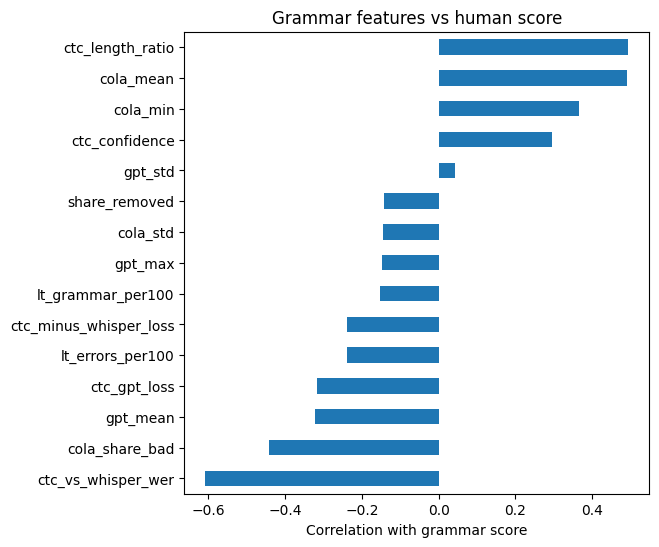

In [18]:
# how much does each grammar feature agree with the human score? (training clips only)
corr = grammar_feats.iloc[:n_train].apply(lambda col: pearsonr(col.fillna(col.median()), y)[0]).sort_values()
corr.plot.barh(figsize=(6, 6))
plt.xlabel("Correlation with grammar score")
plt.title("Grammar features vs human score")
plt.show()

In [19]:
def load_whisper_encoder(dev):
    fe = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")
    return fe, WhisperModel.from_pretrained("openai/whisper-small").encoder.to(dev).eval()

def whisper_embed(paths, dev, models):
    fe, encoder = models
    out = []
    for path in tqdm(paths, desc=dev):
        audio = librosa.load(path, sr=16000)[0]
        vecs, weights = [], []
        for start in range(0, len(audio), 30 * 16000):        # Whisper takes 30 s at a time
            chunk = audio[start:start + 30 * 16000]
            if start > 0 and len(chunk) < 2 * 16000:
                continue
            feats = fe(chunk, sampling_rate=16000, return_tensors="pt").input_features.to(dev)
            with torch.no_grad():
                hidden = encoder(feats, output_hidden_states=True).hidden_states
            n_frames = int(np.ceil(len(chunk) / 320))          # 50 frames per second of real audio
            v = torch.stack([hidden[l][0, :n_frames].mean(0) for l in range(8, 13)]).mean(0)
            vecs.append(v.cpu().numpy())
            weights.append(n_frames)
        out.append(np.average(vecs, axis=0, weights=weights))
    return out

if os.path.exists("whisper_emb.npy"):
    whisper_emb = np.load("whisper_emb.npy")
else:
    whisper_emb = np.array(on_all_gpus(whisper_embed, list(data["path"]), load_whisper_encoder))
    np.save("whisper_emb.npy", whisper_emb)
print(whisper_emb.shape)

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

cuda:0:   0%|          | 0/493 [00:00<?, ?it/s]

cuda:1:   0%|          | 0/492 [00:00<?, ?it/s]

(985, 768)


In [20]:
def load_wavlm(dev):
    wfe = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
    return wfe, WavLMModel.from_pretrained("microsoft/wavlm-base-plus").to(dev).eval()

def wavlm_embed(paths, dev, models):
    wfe, wavlm = models
    out = []
    for path in tqdm(paths, desc=dev):
        audio = librosa.load(path, sr=16000)[0]
        x = wfe(audio, sampling_rate=16000, return_tensors="pt").input_values.to(dev)
        with torch.no_grad():
            hidden = wavlm(x, output_hidden_states=True).hidden_states
        h = torch.stack([hidden[l][0] for l in range(7, 11)]).mean(0)
        out.append(torch.cat([h.mean(0), h.std(0)]).cpu().numpy())
    return out

if os.path.exists("wavlm_emb.npy"):
    wavlm_emb = np.load("wavlm_emb.npy")
else:
    wavlm_emb = np.array(on_all_gpus(wavlm_embed, list(data["path"]), load_wavlm))
    np.save("wavlm_emb.npy", wavlm_emb)
print(wavlm_emb.shape)

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

cuda:0:   0%|          | 0/493 [00:00<?, ?it/s]

cuda:1:   0%|          | 0/492 [00:00<?, ?it/s]

(985, 1536)


In [21]:
# the three feature sets (as arrays; first n_train rows are train, the rest are test)
feature_sets = {
    "hand": hand_feats.replace([np.inf, -np.inf], np.nan).values,
    "whisper": whisper_emb,
    "wavlm": wavlm_emb,
}

def xgb_model():
    return make_pipeline(SimpleImputer(strategy="median"),
                         XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=5,
                                      subsample=0.8, colsample_bytree=0.6, reg_alpha=1, reg_lambda=5))

def ridge_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(1, 5, 16)))

def svr_model():
    return make_pipeline(StandardScaler(), PCA(64), SVR(C=2, epsilon=0.2))

models = {
    "hand + XGBoost": ("hand", xgb_model),
    "whisper + Ridge": ("whisper", ridge_model),
    "whisper + SVR": ("whisper", svr_model),
    "wavlm + Ridge": ("wavlm", ridge_model),
    "wavlm + SVR": ("wavlm", svr_model),
}

oof = {}            # out-of-fold predictions on the training clips
test_pred = {}      # predictions on the test clips
train_pred = {}     # predictions on the training clips from a model trained on all of them

for name, (fs, make_model) in models.items():
    X = feature_sets[fs]
    X_train, X_test = X[:n_train], X[n_train:]
    oof_all = np.zeros((3, n_train))
    test_sum = np.zeros(len(X_test))
    for repeat in range(3):
        for tr, va in KFold(5, shuffle=True, random_state=repeat).split(X_train):
            m = make_model().fit(X_train[tr], y[tr])
            oof_all[repeat, va] = m.predict(X_train[va])
            test_sum += m.predict(X_test) / 15
    oof[name] = oof_all.mean(axis=0)
    test_pred[name] = test_sum
    train_pred[name] = make_model().fit(X_train, y).predict(X_train)
    print(f"{name:18s} CV RMSE = {rmse(y, np.clip(oof[name], 0, 5)):.4f}")

hand + XGBoost     CV RMSE = 0.6999
whisper + Ridge    CV RMSE = 0.5702
whisper + SVR      CV RMSE = 0.5421
wavlm + Ridge      CV RMSE = 0.5461
wavlm + SVR        CV RMSE = 0.5549


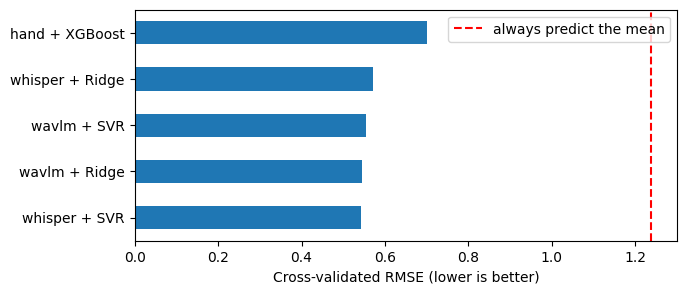

In [22]:
results = pd.Series({n: rmse(y, np.clip(p, 0, 5)) for n, p in oof.items()}).sort_values()
results.plot.barh(figsize=(7, 3))
plt.axvline(baseline_rmse, color="red", linestyle="--", label="always predict the mean")
plt.xlabel("Cross-validated RMSE (lower is better)")
plt.legend()
plt.show()

In [23]:
names = list(models)
oof_matrix = np.column_stack([oof[n] for n in names])
test_matrix = np.column_stack([test_pred[n] for n in names])
train_matrix = np.column_stack([train_pred[n] for n in names])

# honest estimate of the combined model: cross-validate the weights as well
stack_oof = np.zeros(n_train)
for tr, va in KFold(5, shuffle=True, random_state=99).split(oof_matrix):
    stack_oof[va] = LinearRegression(positive=True).fit(oof_matrix[tr], y[tr]).predict(oof_matrix[va])
stack_oof = np.clip(stack_oof, 0, 5)

stacker = LinearRegression(positive=True).fit(oof_matrix, y)
print("Weights:", dict(zip(names, stacker.coef_.round(3))), "| intercept:", round(stacker.intercept_, 3))

simple_average = np.clip(oof_matrix.mean(axis=1), 0, 5)
print("Average of the models   CV RMSE:", round(rmse(y, simple_average), 4))
print("Weighted combination    CV RMSE:", round(rmse(y, stack_oof), 4))

Weights: {'hand + XGBoost': np.float64(0.177), 'whisper + Ridge': np.float64(0.0), 'whisper + SVR': np.float64(0.475), 'wavlm + Ridge': np.float64(0.39), 'wavlm + SVR': np.float64(0.039)} | intercept: -0.28
Average of the models   CV RMSE: 0.521
Weighted combination    CV RMSE: 0.5064


In [24]:
# clips with score 0 are the very noisy ones: does the model handle them?
zero = y == 0
print("clips with score 0:", zero.sum(), "of", n_train)
snr = audio_feats["snr_db"].values
print("mean SNR (dB), score-0 clips:", snr[:n_train][zero].mean().round(1), "| other clips:", snr[:n_train][~zero].mean().round(1))
print("mean predicted score for the score-0 clips:", stack_oof[zero].mean().round(2), "(actual 0)")
print("share of score-0 clips predicted below 1:", (stack_oof[zero] < 1).mean().round(2))
print("test clips mean SNR (dB):", snr[n_train:].mean().round(1), "| train:", snr[:n_train].mean().round(1))

clips with score 0: 37 of 769
mean SNR (dB), score-0 clips: 2.7 | other clips: 42.0
mean predicted score for the score-0 clips: 0.12 (actual 0)
share of score-0 clips predicted below 1: 0.97
test clips mean SNR (dB): 35.2 | train: 40.1


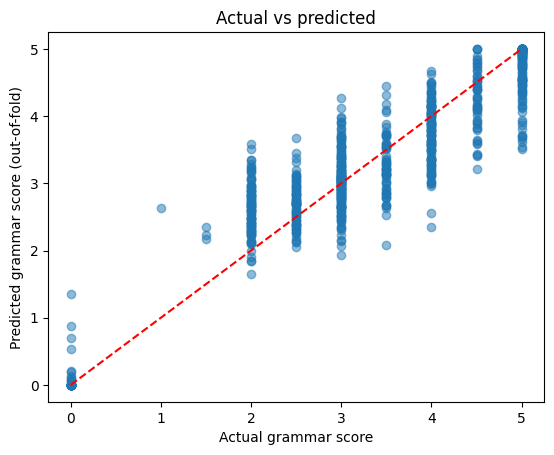

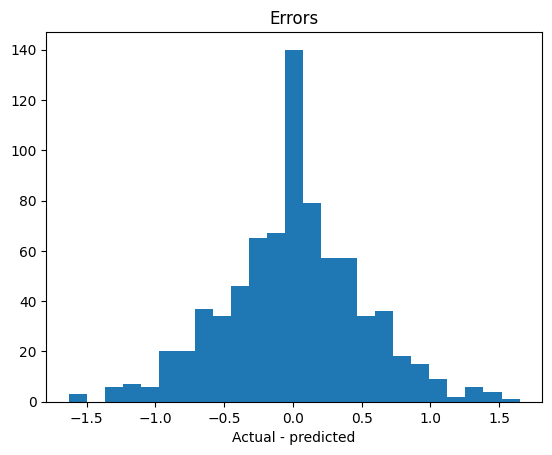

In [25]:
plt.scatter(y, stack_oof, alpha=0.5)
plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("Actual grammar score")
plt.ylabel("Predicted grammar score (out-of-fold)")
plt.title("Actual vs predicted")
plt.show()

plt.hist(y - stack_oof, bins=25)
plt.xlabel("Actual - predicted")
plt.title("Errors")
plt.show()

In [26]:
groups = {
    "cola": [c for c in grammar_feats.columns if c.startswith("cola")],
    "gpt2": [c for c in grammar_feats.columns if c.startswith("gpt")],
    "languagetool": [c for c in grammar_feats.columns if c.startswith("lt_")],
    "wav2vec2 comparison": [c for c in grammar_feats.columns if c.startswith("ctc")],
    "disfluency": ["share_removed"],
}

def cv_rmse(columns):
    X = grammar_feats[columns].replace([np.inf, -np.inf], np.nan).values[:n_train]
    pred = np.zeros(n_train)
    for tr, va in KFold(5, shuffle=True, random_state=0).split(X):
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          RidgeCV(alphas=np.logspace(-1, 4, 20))).fit(X[tr], y[tr])
        pred[va] = m.predict(X[va])
    return rmse(y, np.clip(pred, 0, 5))

all_cols = list(grammar_feats.columns)
print(f"all grammar features: {cv_rmse(all_cols):.4f}")
for g, cols in groups.items():
    left = [c for c in all_cols if c not in cols]
    print(f"without {g:20s}: {cv_rmse(left):.4f}")

all grammar features: 0.8045
without cola                : 0.8569
without gpt2                : 0.8056
without languagetool        : 0.8044
without wav2vec2 comparison : 1.0694
without disfluency          : 0.8048


In [27]:
final_cv = stack_oof
train_final = np.clip(stacker.predict(train_matrix), 0, 5)
test_final = np.clip(stacker.predict(test_matrix), 0, 5)

print("Training RMSE (model trained on all 769 clips)    :", round(rmse(y, train_final), 4))
print("Cross-validated RMSE (clips the model had not seen):", round(rmse(y, final_cv), 4))
print("Baseline RMSE (always predict the mean)           :", round(baseline_rmse, 4))
print("Cross-validated Pearson correlation               :", round(pearsonr(y, final_cv)[0], 4))

Training RMSE (model trained on all 769 clips)    : 0.2535
Cross-validated RMSE (clips the model had not seen): 0.5064
Baseline RMSE (always predict the mean)           : 1.2382
Cross-validated Pearson correlation               : 0.913


In [28]:
submission = pd.DataFrame({"filename": test["filename"], "label": test_final})

# the file is built from test.csv (216 clips); sample_submission.csv has fewer rows
sample = pd.read_csv(DATA + "sample_submission.csv")
print("rows: submission", len(submission), "| sample submission", len(sample))
print("sample submission files found in our submission:", sample.iloc[:, 0].isin(submission["filename"]).sum(), "of", len(sample))
print("NaN predictions:", submission["label"].isna().sum())
print("min / max:", submission["label"].min(), submission["label"].max())

submission.to_csv("submission.csv", index=False)
submission[submission["filename"].isin(sample.iloc[:, 0])].to_csv("submission_sample_rows_only.csv", index=False)
print(submission.head())
print(submission["label"].describe())

rows: submission 216 | sample submission 204
sample submission files found in our submission: 25 of 204
NaN predictions: 0
min / max: 1.782138586965448 5.0
        filename     label
0  audio_128.wav  3.153124
1  audio_156.wav  4.006098
2   audio_19.wav  4.575057
3  audio_108.wav  2.205264
4  audio_206.wav  2.192850
count    216.000000
mean       3.279831
std        0.798364
min        1.782139
25%        2.665373
50%        3.146100
75%        3.732364
max        5.000000
Name: label, dtype: float64
